# =============================================
# 간단한 데이터 사용
# (데이터는 data.csv화일 사용)

In [1]:
# 메모리에 있는 모든 변수를 지우고 새롭게 시작함
all = [var for var in globals() if var[0] != "_"]
for var in all:
    del globals()[var]

In [2]:
# 사용되는 패키지을 읽어들임
# pip install numpy pandas

import numpy as np
import pandas as pd
import random
import calendar
import matplotlib.pyplot as plt
from scipy.stats import mstats, skew, kurtosis
import statsmodels.api as sm
import seaborn as sns
from statsmodels.graphics.gofplots import qqline
import math
import warnings
warnings.filterwarnings('ignore')

In [3]:
# # Colab 사용할 경우 구글드라이버 폴더에 접근하게 함
from google.colab import drive
drive.mount('/gdrive')

Mounted at /gdrive


In [4]:
sdata = pd.read_csv("/gdrive//MyDrive/QuantFinance/data.csv", index_col=0)
# sdata = pd.read_csv("data.csv",index_col=0)   # 자신의 컴퓨터에 설치된 파이썬을 사용하는 경우. 파이썬 코드와 데이터 화일의 위치가 동일해야함. 아니면 폴더 경로를 명시
sdata = sdata.dropna(axis=0)   # 입력이 없는 열은 삭제함, axis=1로허면 어떻게 될까?
n = sdata.shape[0]   # 행의 수자   [1]인 경우 열의 수자

sdata.info()   # 읽어들인 데이터의 정보

<class 'pandas.core.frame.DataFrame'>
Index: 167 entries, 2006-09-29 to 2020-07-31
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   RKOSPI     167 non-null    float64
 1   RLotte     167 non-null    float64
 2   RManho     167 non-null    float64
 3   RMeritz    167 non-null    float64
 4   RSamsung   167 non-null    float64
 5   RSamyoung  167 non-null    float64
 6   RF_M       167 non-null    float64
 7   RFGN_REV   167 non-null    float64
 8   RIPD       167 non-null    float64
 9   RCPI       167 non-null    float64
 10  RSP500     167 non-null    float64
 11  ROil       167 non-null    float64
 12  Rshanghai  167 non-null    float64
 13  KOSPI      167 non-null    float64
 14  Lotte      167 non-null    float64
 15  Manho      167 non-null    float64
 16  Meritz     167 non-null    float64
 17  Samsung    167 non-null    float64
 18  Samyoung   167 non-null    float64
 19  rf         167 non-null    float64
 20 

Mean: 0.15605988023952097
Median: 0.153
Standard Deviation: 0.34553155663950663
Variance: 0.11939205663372057
Minimum: -0.748
Maximum: 1.178
Skewness: 0.21320124397569729
Kurtosis: 0.13453041960057854


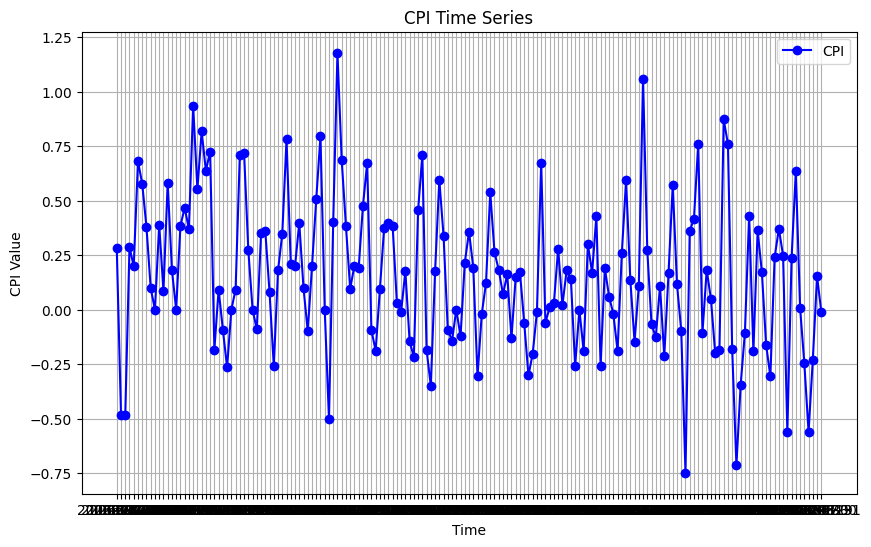

AR(p) Model Summary:
                               SARIMAX Results                                
Dep. Variable:                   RCPI   No. Observations:                  167
Model:                 ARIMA(1, 0, 0)   Log Likelihood                 -51.235
Date:                Thu, 11 Sep 2025   AIC                            108.469
Time:                        09:20:34   BIC                            117.823
Sample:                    09-29-2006   HQIC                           112.266
                         - 07-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1560      0.037      4.271      0.000       0.084       0.228
ar.L1          0.2973      0.075      3.944      0.000       0.150       0.445
sigma2         0.1081      0.01

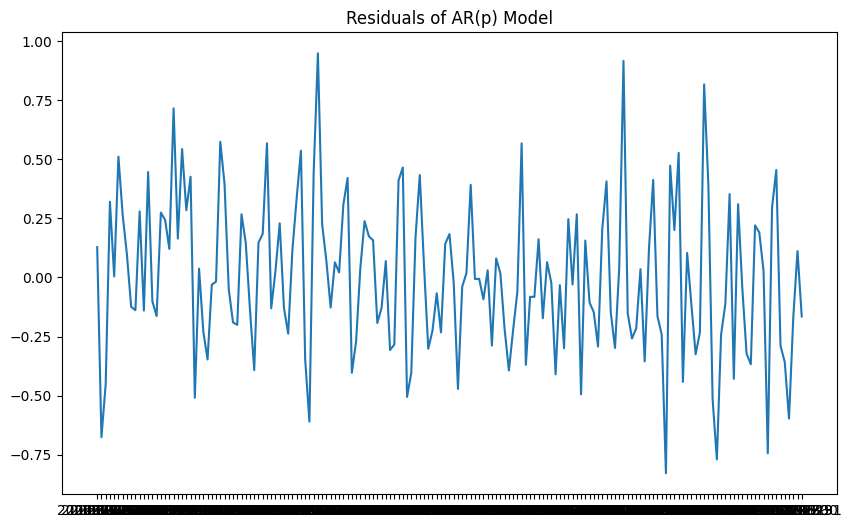

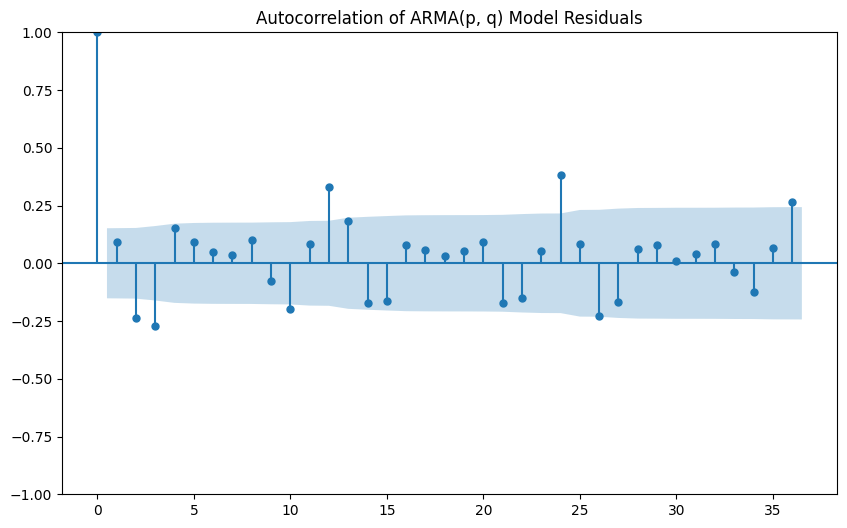


MA(q) Model Summary:
                               SARIMAX Results                                
Dep. Variable:                   RCPI   No. Observations:                  167
Model:                 ARIMA(0, 0, 1)   Log Likelihood                 -47.914
Date:                Thu, 11 Sep 2025   AIC                            101.828
Time:                        09:20:36   BIC                            111.182
Sample:                    09-29-2006   HQIC                           105.624
                         - 07-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1562      0.035      4.524      0.000       0.089       0.224
ma.L1          0.3690      0.075      4.944      0.000       0.223       0.515
sigma2         0.1038      0.0

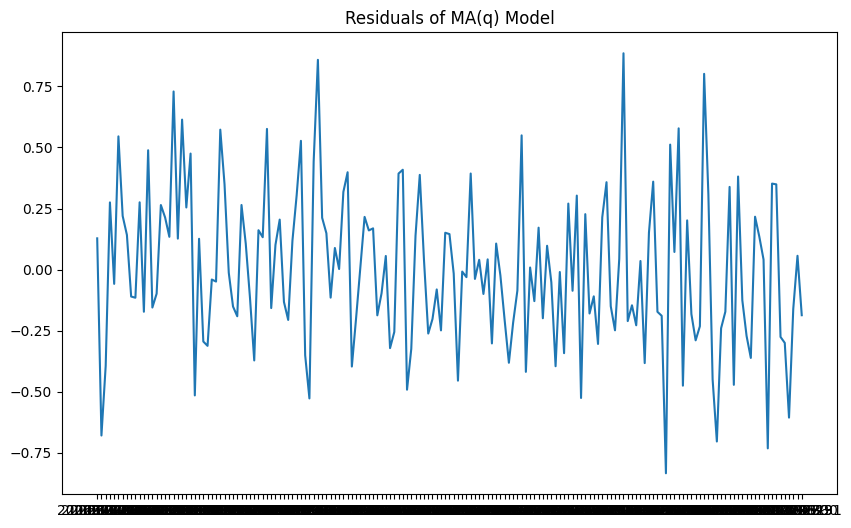

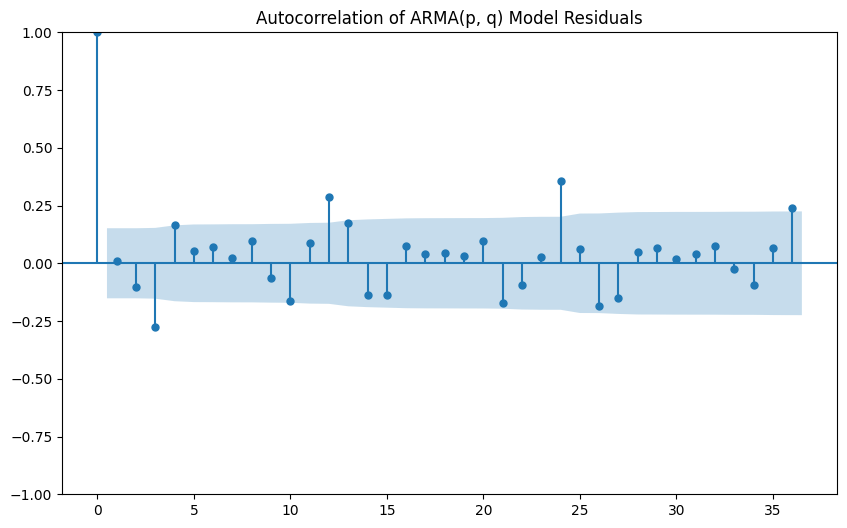


ARMA(p, q) Model Summary:
                               SARIMAX Results                                
Dep. Variable:                   RCPI   No. Observations:                  167
Model:                 ARIMA(1, 0, 1)   Log Likelihood                 -47.896
Date:                Thu, 11 Sep 2025   AIC                            103.792
Time:                        09:20:38   BIC                            116.264
Sample:                    09-29-2006   HQIC                           108.854
                         - 07-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1562      0.035      4.462      0.000       0.088       0.225
ar.L1          0.0262      0.214      0.122      0.903      -0.394       0.446
ma.L1          0.3510    

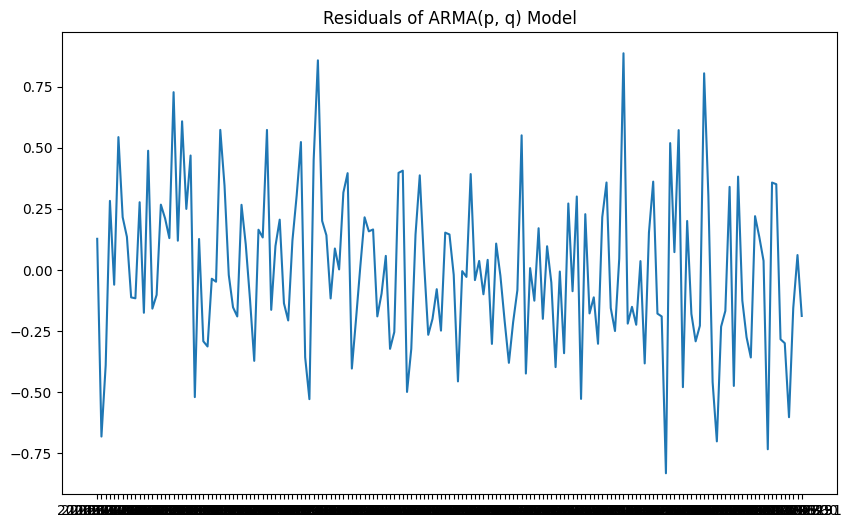

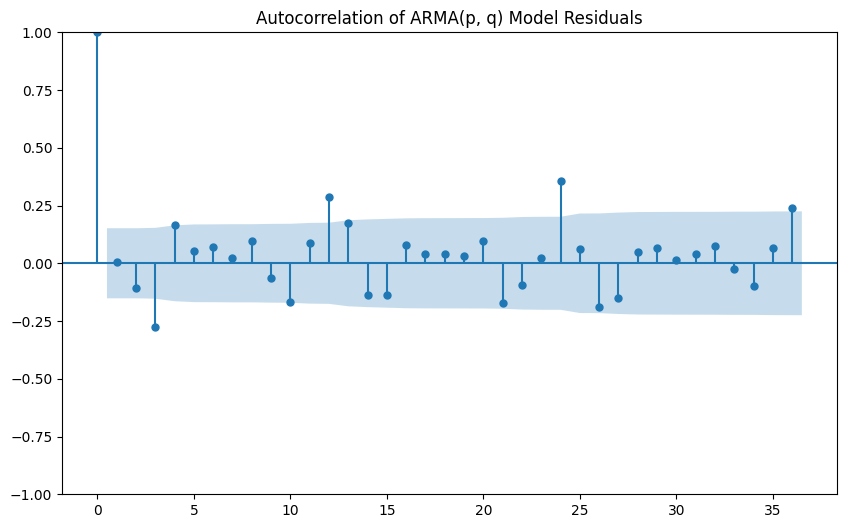

                                     SARIMAX Results                                      
Dep. Variable:                               RCPI   No. Observations:                  167
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                 -44.489
Date:                            Thu, 11 Sep 2025   AIC                             94.978
Time:                                    09:20:39   BIC                            104.332
Sample:                                09-29-2006   HQIC                            98.774
                                     - 07-31-2020                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2880      0.075      3.859      0.000       0.142       0.434
ar.S.L12       0.4300      0.074   

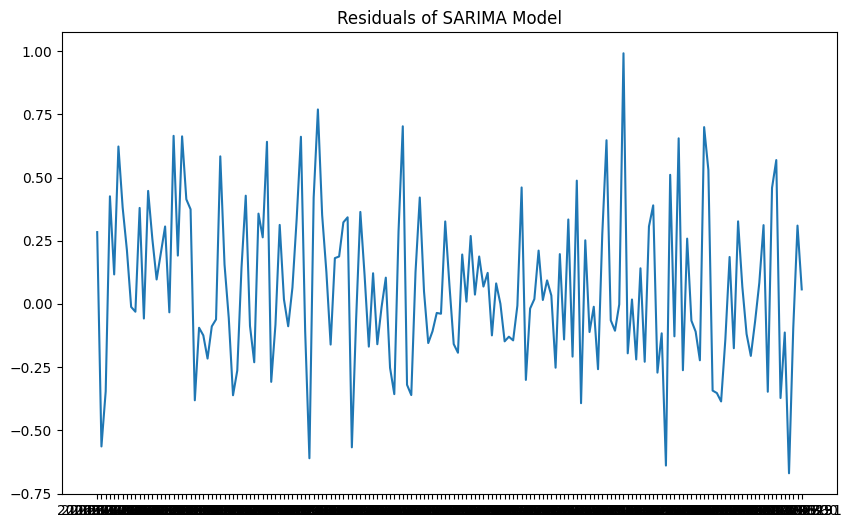

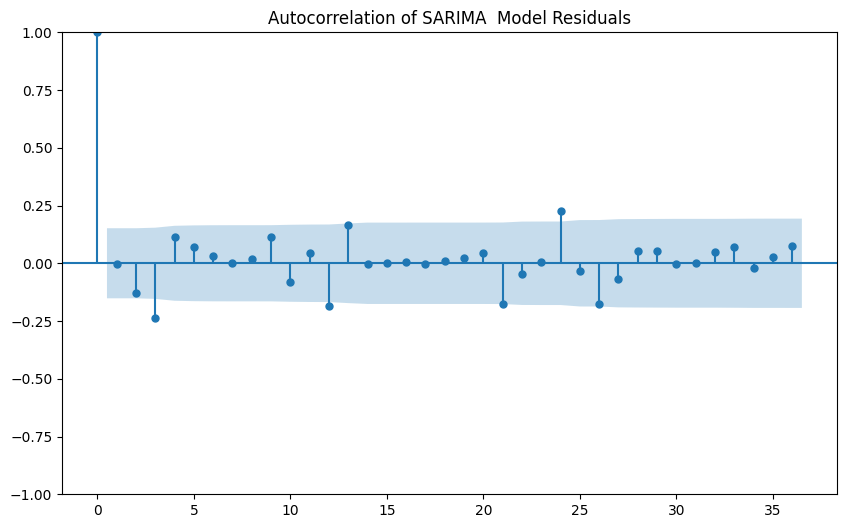

In [5]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# The most general form of the model is SARIMAX(p, d, q)x(P, D, Q, s).
# autoregressive models: AR(p)
# moving average models: MA(q)
# mixed autoregressive moving average models: ARMA(p, q)
# integration models: ARIMA(p, d, q)
# seasonal models: SARIMA(P, D, Q, s)
# regression with errors that follow one of the above ARIMA-type models

# Select a Variable
X = sdata['RCPI']


# =================================================================
print("=================================================================")
# Calculating basic statistical characteristics
statistics = {
    "Mean": X.mean(),
    "Median": X.median(),
    "Standard Deviation": X.std(),
    "Variance": X.var(),
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Skewness": X.skew(),
    "Kurtosis": X.kurtosis()
}

# Displaying the result
for stat, value in statistics.items():
    print(f"{stat}: {value}")

# Plotting the time series
plt.figure(figsize=(10, 6))
plt.plot(X, marker='o', linestyle='-', color='b', label='CPI')
plt.title('CPI Time Series')
plt.xlabel('Time')
plt.ylabel('CPI Value')
plt.legend()
plt.grid(True)
plt.show()

# =================================================================
print("=================================================================")
# Assuming the time series is a pandas Series containing your time series data
# AR(p) model
p = 1  # You can change this value to specify the order of AR

ar_model = sm.tsa.ARIMA(X, order=(p, 0, 0))
ar_result = ar_model.fit()
print("AR(p) Model Summary:")
print(ar_result.summary())

# Plotting AR(p) model residuals
plt.figure(figsize=(10, 6))
plt.plot(ar_result.resid)
plt.title("Residuals of AR(p) Model")
plt.show()

# Plotting autocorrelation of ARMA(p, q) model residuals over 36 lags
fig, ax = plt.subplots(figsize=(10, 6))
sm.graphics.tsa.plot_acf(ar_result.resid, lags=36, ax=ax)
plt.title("Autocorrelation of ARMA(p, q) Model Residuals")
plt.show()


# =================================================================
print("=================================================================")
# MA(q) model
q = 1  # You can change this value to specify the order of MA
ma_model = sm.tsa.ARIMA(X, order=(0, 0, q))
ma_result = ma_model.fit()
print("\nMA(q) Model Summary:")
print(ma_result.summary())

# Plotting MA(q) model residuals
plt.figure(figsize=(10, 6))
plt.plot(ma_result.resid)
plt.title("Residuals of MA(q) Model")
plt.show()

# Plotting autocorrelation of ARMA(p, q) model residuals over 36 lags
fig, ax = plt.subplots(figsize=(10, 6))
sm.graphics.tsa.plot_acf(ma_result.resid, lags=36, ax=ax)
plt.title("Autocorrelation of ARMA(p, q) Model Residuals")
plt.show()


# =================================================================
print("=================================================================")
# ARMA(p, q) model
p = 1  # You can change this value to specify the order of AR
q = 1  # You can change this value to specify the order of MA
arma_model = sm.tsa.ARIMA(X, order=(p, 0, q))
arma_result = arma_model.fit()
print("\nARMA(p, q) Model Summary:")
print(arma_result.summary())

# Plotting ARMA(p, q) model residuals
plt.figure(figsize=(10, 6))
plt.plot(arma_result.resid)
plt.title("Residuals of ARMA(p, q) Model")
plt.show()

# Plotting autocorrelation of ARMA(p, q) model residuals over 36 lags
fig, ax = plt.subplots(figsize=(10, 6))
sm.graphics.tsa.plot_acf(arma_result.resid, lags=36, ax=ax)
plt.title("Autocorrelation of ARMA(p, q) Model Residuals")
plt.show()


# =================================================================
print("=================================================================")
# Set the non-seasonal (p, d, q) and seasonal (P, D, Q, s) parameters
p, d, q = 1, 0, 0          # Non-seasonal parameters
P, D, Q, s = 1, 0, 0, 12    # Seasonal parameters with period s = 12

# Define and fit the SARIMA model
sarima_model = sm.tsa.SARIMAX(X, order=(p, d, q), seasonal_order=(P, D, Q, s))
sarima_results = sarima_model.fit()

# Print model summary
print(sarima_results.summary())

# Plotting SARIMA model residuals
plt.figure(figsize=(10, 6))
plt.plot(sarima_results.resid)
plt.title("Residuals of SARIMA Model")
plt.show()

# Plotting autocorrelation of SARIMA model residuals over 36 lags
fig, ax = plt.subplots(figsize=(10, 6))
sm.graphics.tsa.plot_acf(sarima_results.resid, lags=36, ax=ax)
plt.title("Autocorrelation of SARIMA  Model Residuals")
plt.show()


Optimal Lag Order:
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        14.78      14.92*   2.635e+06       14.84
1        14.31       15.42   1.643e+06      14.76*
2        14.14       16.22   1.394e+06       14.99
3        14.20       17.25   1.493e+06       15.44
4        13.88       17.90  1.098e+06*       15.51
5        14.15       19.14   1.483e+06       16.17
6        14.17       20.14   1.597e+06       16.60
7        14.25       21.18   1.840e+06       17.07
8        14.47       22.37   2.496e+06       17.68
9        14.50       23.37   2.902e+06       18.10
10       14.28       24.12   2.713e+06       18.27
11       14.10       24.91   2.769e+06       18.49
12       13.90       25.69   2.939e+06       18.69
13       13.50       26.25   2.707e+06       18.68
14      13.44*       27.16   3.834e+06       19.01
--------------------------------------------------
  Summary of

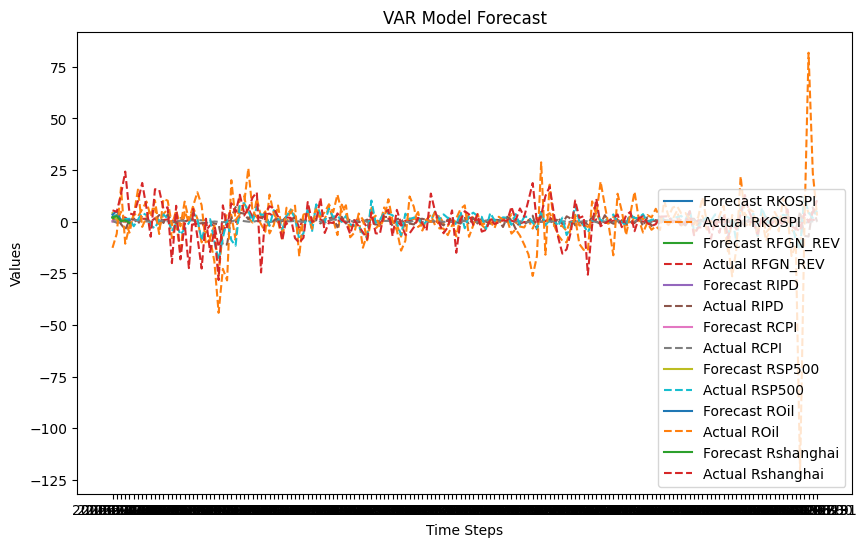

In [6]:
# =================================================================
# Vector Autoregression Model
print("=================================================================")

import pandas as pd
from statsmodels.tsa.api import VAR
import matplotlib.pyplot as plt


X = sdata[['RKOSPI', 'RFGN_REV', 'RIPD', 'RCPI', 'RSP500', 'ROil', 'Rshanghai']]

model = VAR(X)
lags = model.select_order()  # Automatically select optimal lag order
print("Optimal Lag Order:")
print(lags.summary())

# optimal_lag = lags.selected_orders['bic']  # Use AIC criterion to select the lag
optimal_lag = 2
var_model = model.fit(optimal_lag)

# Summary of the VAR model
print(var_model.summary())

# Forecasting
forecast_steps = 5
forecast = var_model.forecast(X.values[-optimal_lag:], steps=forecast_steps)
forecast_df = pd.DataFrame(forecast, columns=['RKOSPI', 'RFGN_REV', 'RIPD', 'RCPI', 'RSP500', 'ROil', 'Rshanghai'])

# Plot the forecast
plt.figure(figsize=(10, 6))
for column in forecast_df.columns:
    plt.plot(forecast_df[column], label=f"Forecast {column}")
    plt.plot(X[column], label=f"Actual {column}", linestyle="--")

plt.legend()
plt.title("VAR Model Forecast")
plt.xlabel("Time Steps")
plt.ylabel("Values")
plt.show()

Data shape: (167, 2)
Selected lag order: 2
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 11, Sep, 2025
Time:                     09:20:42
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                    7.38838
Nobs:                     165.000    HQIC:                   7.27655
Log likelihood:          -1052.26    FPE:                    1339.66
AIC:                      7.20014    Det(Omega_mle):         1262.02
--------------------------------------------------------------------
Results for equation X
           coefficient       std. error           t-stat            prob
------------------------------------------------------------------------
const         0.258873         0.639094            0.405           0.685
L1.X          0.129167         0.090186            1.432           0.152
L1.Y         -0.074935         0.142327           -0.

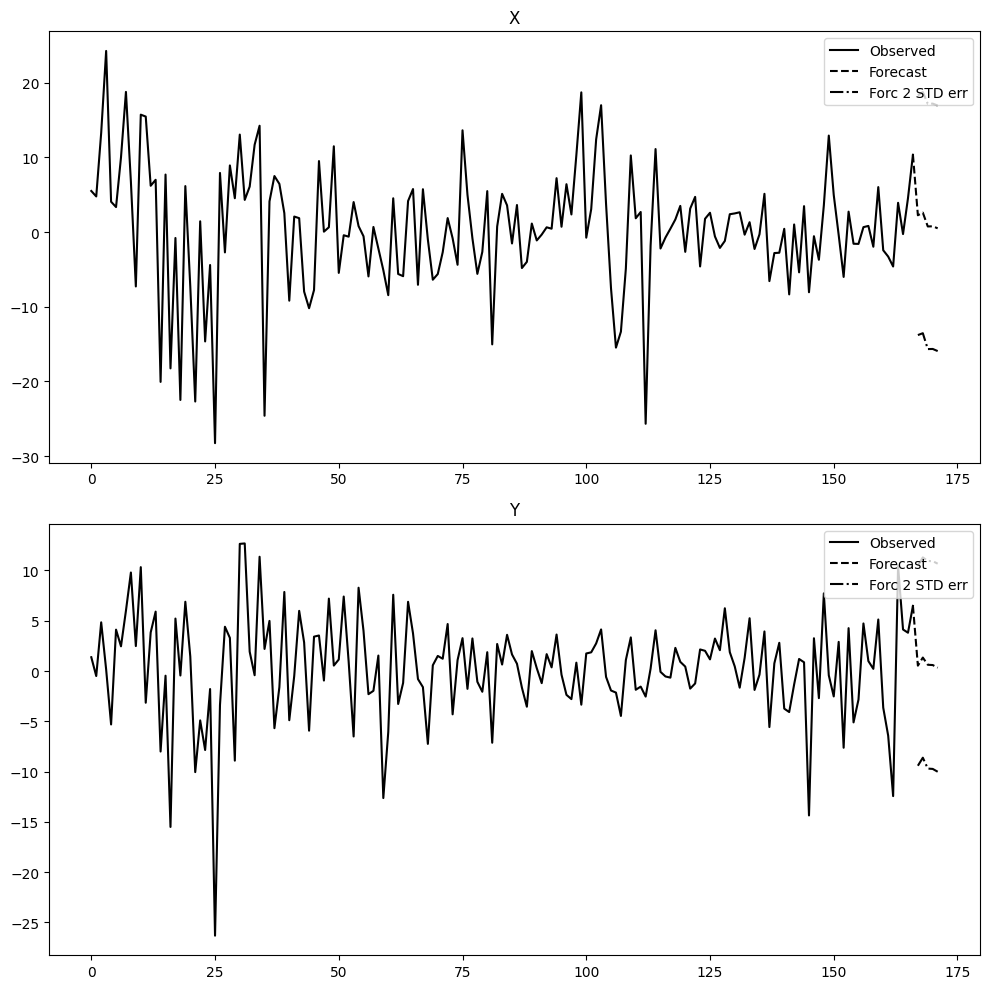

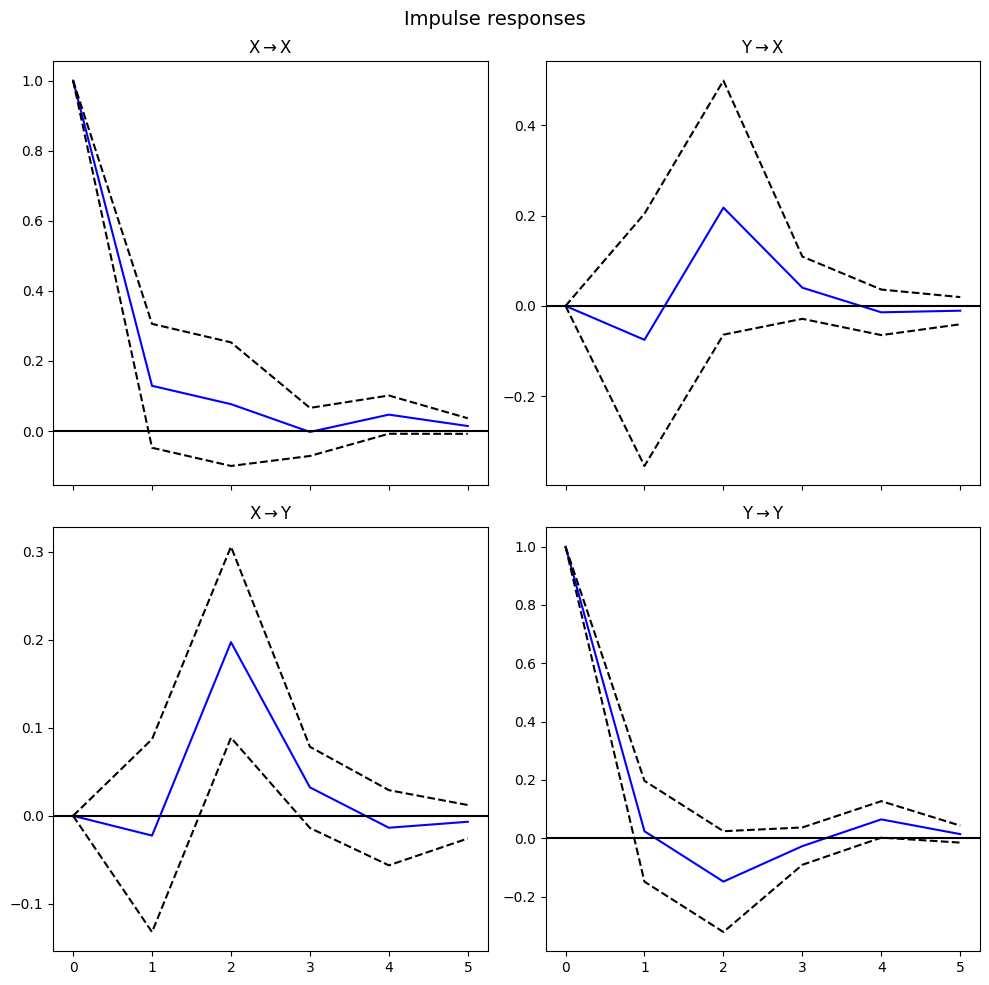

Y -> X

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.3366  , p=0.5626  , df_denom=163, df_num=1
ssr based chi2 test:   chi2=0.3428  , p=0.5582  , df=1
likelihood ratio test: chi2=0.3425  , p=0.5584  , df=1
parameter F test:         F=0.3366  , p=0.5626  , df_denom=163, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.4090  , p=0.2474  , df_denom=160, df_num=2
ssr based chi2 test:   chi2=2.9061  , p=0.2339  , df=2
likelihood ratio test: chi2=2.8808  , p=0.2368  , df=2
parameter F test:         F=1.4090  , p=0.2474  , df_denom=160, df_num=2
X -> Y

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.0072  , p=0.9327  , df_denom=163, df_num=1
ssr based chi2 test:   chi2=0.0073  , p=0.9320  , df=1
likelihood ratio test: chi2=0.0073  , p=0.9320  , df=1
parameter F test:         F=0.0072  , p=0.9327  , df_denom=163, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=6.4656

In [7]:
# Prepare the DataFrame
df = pd.DataFrame()
df['X'] = sdata["Rshanghai"]  # X
df['Y'] = sdata["RKOSPI"]  # Y
df = df.dropna()

# Check data shape
print(f"Data shape: {df.shape}")

# Fit the VAR model
fit = sm.tsa.VAR(df).fit(maxlags=3, ic='aic')  # Use maxlags=2 if dataset is small
print(f"Selected lag order: {fit.k_ar}")
print(fit.summary())

# Forecast
forecast_num = 5
if fit.k_ar > 0:  # Only plot if lag order is valid
    fit.plot_forecast(forecast_num)
    plt.tight_layout()
    plt.show()

    # Impulse Response Function (IRF)
    fit.irf(forecast_num).plot()
    plt.tight_layout()
    plt.show()
else:
    print("Forecasting skipped due to insufficient lag order.")

# Granger Causality Test
print('Y -> X')  # Y => X
granger_result1 = sm.tsa.stattools.grangercausalitytests(df[['X', 'Y']], maxlag=fit.k_ar, verbose=True)

print('X -> Y')  # X => Y
granger_result2 = sm.tsa.stattools.grangercausalitytests(df[['Y', 'X']], maxlag=fit.k_ar, verbose=True)


Mean of Series 1: 0.01933205582232549
Variance of Series 1: 0.9579049897315173
Mean of Series 2: 0.07083623724915591
Variance of Series 2: 0.9939203194154921

Correlation Matrix:
         Series1  Series2
Series1   1.0000  -0.0404
Series2  -0.0404   1.0000
          Series1   Series2
Series1  1.000000  0.825499
Series2  0.825499  1.000000


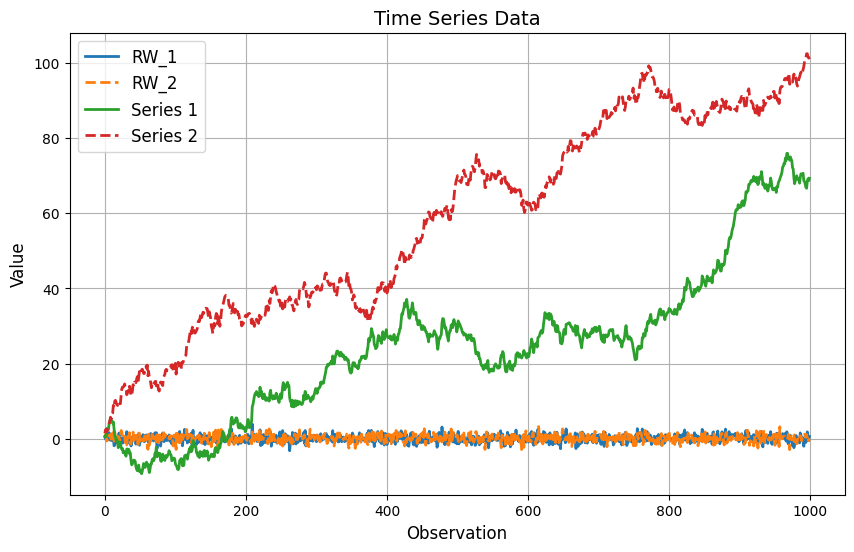

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.681
Method:                 Least Squares   F-statistic:                     2135.
Date:                Thu, 11 Sep 2025   Prob (F-statistic):          3.73e-250
Time:                        09:20:43   Log-Likelihood:                -3870.8
No. Observations:                1000   AIC:                             7746.
Df Residuals:                     998   BIC:                             7755.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -12.0320      0.875    -13.746      0.0

In [8]:
#  ============================================
# Spurious Regression
#  ============================================

#  ------------------------------------------------
# Generate Randomwalk with Drift
# Set the seed for reproducibility
np.random.seed(42)

# Parameters for the random walk with drift
n_obs = 1000
drift1 = 0.05
drift2 = 0.03

# Generate random steps for the random walk
random_steps1 = np.random.normal(0, 1, n_obs)
random_steps2 = np.random.normal(0, 1, n_obs)

# Create the random walks with drift
series1 = np.cumsum(drift1 + random_steps1)
series2 = np.cumsum(drift2 + random_steps2)


#  ------------------------------------------------
# Statistical Properties
# Calculate mean and variance
mean_series1 = np.mean(random_steps1)
variance_series1 = np.var(random_steps1)
mean_series2 = np.mean(random_steps2)
variance_series2 = np.var(random_steps2)

# Create a DataFrame for the series
data1 = pd.DataFrame({'Series1': random_steps1, 'Series2': random_steps2})

# Create a DataFrame for the unit root process
data2 = pd.DataFrame({'Series1': series1, 'Series2': series2})

# Calculate the correlation matrix
correlation_matrix_S = data1.corr()
correlation_matrix_N = data2.corr()

# Print the results
print(f"Mean of Series 1: {mean_series1}")
print(f"Variance of Series 1: {variance_series1}")
print(f"Mean of Series 2: {mean_series2}")
print(f"Variance of Series 2: {variance_series2}")
print("\nCorrelation Matrix:")
print(correlation_matrix_S)
print(correlation_matrix_N)


#  ------------------------------------------------
# Plot the two time series
plt.figure(figsize=(10, 6))
plt.plot(random_steps1, label='RW_1', linestyle='-', linewidth=2)
plt.plot(random_steps2, label='RW_2', linestyle='--', linewidth=2)
plt.plot(series1, label='Series 1', linestyle='-', linewidth=2)
plt.plot(series2, label='Series 2', linestyle='--', linewidth=2)

# Add titles and labels
plt.title('Time Series Data', fontsize=14)
plt.xlabel('Observation', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True)

# Display the plot
plt.show()




#  ------------------------------------------------
# Spurious Regression
X = sm.add_constant(series2)  # Add a constant for the intercept
model = sm.OLS(series1, X).fit()

# Extract regression results
coef = model.params[1]
p_value = model.pvalues[1]
results_summary = model.summary()
coef_significant = p_value < 0.05

# Print the summary and results
print(results_summary)
print(f"Coefficient for x1: {coef}")
print(f"P-value for x1: {p_value}")
print(f"Is the coefficient significant? {'Yes' if coef_significant else 'No'}")

In [9]:
#  ============================================
# The Augmented Dickey-Fuller (ADF) test
#  ============================================

from statsmodels.tsa.stattools import adfuller

# Perform the Augmented Dickey-Fuller test on Series 1
adf_result_series1 = adfuller(series1)
print("ADF Test for Series 1:")
print(f"Test Statistic: {adf_result_series1[0]}")
print(f"p-value: {adf_result_series1[1]}")
print(f"Lags Used: {adf_result_series1[2]}")
print(f"Number of Observations: {adf_result_series1[3]}")
print("Critical Values:")
for key, value in adf_result_series1[4].items():
    print(f"   {key}: {value}")
print(f"Is Series 1 Stationary? {'Yes' if adf_result_series1[1] < 0.05 else 'No'}\n")

# Perform the Augmented Dickey-Fuller test on Series 2
adf_result_series2 = adfuller(series2)
print("ADF Test for Series 2:")
print(f"Test Statistic: {adf_result_series2[0]}")
print(f"p-value: {adf_result_series2[1]}")
print(f"Lags Used: {adf_result_series2[2]}")
print(f"Number of Observations: {adf_result_series2[3]}")
print("Critical Values:")
for key, value in adf_result_series2[4].items():
    print(f"   {key}: {value}")
print(f"Is Series 2 Stationary? {'Yes' if adf_result_series2[1] < 0.05 else 'No'}")

ADF Test for Series 1:
Test Statistic: 0.35832645286017706
p-value: 0.9798677974803642
Lags Used: 0
Number of Observations: 999
Critical Values:
   1%: -3.4369127451400474
   5%: -2.864437475834273
   10%: -2.568312754566378
Is Series 1 Stationary? No

ADF Test for Series 2:
Test Statistic: -1.4403991541930075
p-value: 0.5627624448674772
Lags Used: 0
Number of Observations: 999
Critical Values:
   1%: -3.4369127451400474
   5%: -2.864437475834273
   10%: -2.568312754566378
Is Series 2 Stationary? No


In [10]:
import numpy as np
import statsmodels.api as sm

max_lag = 1
y = series1

# First difference of the series
delta_y = np.diff(y)
# Lagged series (y_{t-1})
lagged_y = y[:-1]

# Lagged differences (up to max_lag)
lagged_differences = np.column_stack([np.roll(delta_y, i) for i in range(1, max_lag + 1)])
lagged_differences = lagged_differences[max_lag:]  # Adjust for lag truncation

# Regressors: constant, trend, lagged series, and lagged differences
X = np.column_stack([np.ones(len(lagged_y) - max_lag),  # Constant
                        # np.arange(len(lagged_y) - max_lag),  # Trend
                        lagged_y[max_lag:]])  # Lagged series
                        # lagged_differences],
                        # )  # Lagged differences
y_reg = delta_y[max_lag:]  # Response variable (first differences)

# Run the regression
model = sm.OLS(y_reg, X).fit()

# Display regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.1242
Date:                Thu, 11 Sep 2025   Prob (F-statistic):              0.725
Time:                        09:20:43   Log-Likelihood:                -1395.4
No. Observations:                 998   AIC:                             2795.
Df Residuals:                     996   BIC:                             2805.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0559      0.049      1.152      0.2

In [11]:
# ========================================
# Engle-Granger Two-Step Procedure
# Step 1 (Regression): series1 is regressed on series2 to estimate their long-run relationship. Residuals from this regression are computed.
# Step 2 (ADF Test): The residuals are tested for stationarity using the Augmented Dickey-Fuller (ADF) test. If the residuals are stationary (𝑝<0.05), the series are cointegrated.


X = sm.add_constant(series2)
model = sm.OLS(series1, X).fit()
residuals = model.resid

# Display the regression results
print("Step 1: Regression Results:")
print(model.summary())

# Step 2: Test residuals for stationarity using ADF test
print("\nStep 2: Testing residuals for stationarity (ADF Test):")
adf_result = adfuller(residuals)
print(f"ADF Test Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")
print(f"Lags Used: {adf_result[2]}")
print(f"Number of Observations: {adf_result[3]}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value}")

if adf_result[1] < 0.05:
    print("\nConclusion: Residuals are stationary. The series are cointegrated.")
else:
    print("\nConclusion: Residuals are not stationary. The series are not cointegrated.")

# # Example usage of the Engle-Granger test
# engle_granger_cointegration_test(series1, series2)

# # Granger Causality Test
# print("\nGranger Causality Test Results:")
# granger_results = grangercausalitytests(np.column_stack((series1, series2)), maxlag=5, verbose=True)

Step 1: Regression Results:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.681
Method:                 Least Squares   F-statistic:                     2135.
Date:                Thu, 11 Sep 2025   Prob (F-statistic):          3.73e-250
Time:                        09:20:43   Log-Likelihood:                -3870.8
No. Observations:                1000   AIC:                             7746.
Df Residuals:                     998   BIC:                             7755.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -12.0320   

In [12]:
pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.3/978.3 kB 42.1 MB/s eta 0:00:00


ARCH Model Summary:
                      Constant Mean - ARCH Model Results                      
Dep. Variable:                 RKOSPI   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -511.215
Distribution:                  Normal   AIC:                           1028.43
Method:            Maximum Likelihood   BIC:                           1037.78
                                        No. Observations:                  167
Date:                Thu, Sep 11 2025   Df Residuals:                      166
Time:                        09:20:55   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.3054      0.399      0.766      0

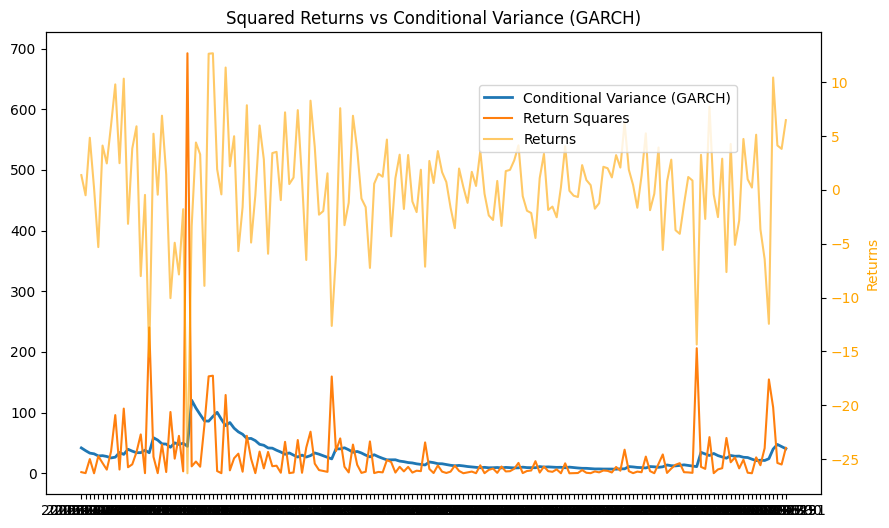

In [13]:
from arch import arch_model


# Generate synthetic data
# np.random.seed(42)
# n_obs = 1000
# data = np.random.normal(size=n_obs)
data = sdata["RKOSPI"]

# ARCH Model
arch_mod = arch_model(data, vol='ARCH', p=1)
arch_fit = arch_mod.fit(disp='off')
print("ARCH Model Summary:")
print(arch_fit.summary())

# GARCH Model
garch_mod = arch_model(data, vol='Garch', p=1, q=1)
garch_fit = garch_mod.fit(disp='off')
print("\nGARCH Model Summary:")
print(garch_fit.summary())

# EGARCH Model
egarch_mod = arch_model(data, vol='EGarch', p=1, q=1)
egarch_fit = egarch_mod.fit(disp='off')
print("\nEGARCH Model Summary:")
print(egarch_fit.summary())

# Plotting the conditional volatility for the GARCH model
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(garch_fit.conditional_volatility**2, label='Conditional Variance (GARCH)', linewidth=2)
ax1.plot(data**2, label='Return Squares')
plt.title('Squared Returns vs Conditional Variance (GARCH)')
plt.grid(False)

ax2 = ax1.twinx()
ax2.plot(data, label='Returns', color='orange', alpha=0.6)
ax2.set_ylabel('Returns', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9), bbox_transform=ax1.transAxes)
plt.show()

In [16]:
!pip install pymc3
# pip install rviz as az

  Using cached pymc3-3.11.6-py3-none-any.whl.metadata (15 kB)
  Using cached deprecat-2.1.3-py2.py3-none-any.whl.metadata (1.6 kB)
  Using cached numpy-1.22.1.zip (11.4 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [15]:
# Stochastoc Volatility Process

import pymc3 as pm
import numpy as np
import matplotlib.pyplot as plt
import arviz as az

# ## Generating SV process
# # Parameters for the stochastic volatility model
# np.random.seed(42)
# n_obs = 1000  # Number of observations
# mu = 0.0  # Drift of returns
# phi = 0.95  # Persistence of volatility
# sigma_eta = 0.2  # Standard deviation of volatility innovations
# sigma_eps = 1.0  # Standard deviation of return noise

# # Simulating the latent volatility process (log-volatility)
# log_volatility = np.zeros(n_obs)
# for t in range(1, n_obs):
#     log_volatility[t] = phi * log_volatility[t-1] + sigma_eta * np.random.normal()

# # Convert log-volatility to volatility
# volatility = np.exp(log_volatility / 2)

# # Simulate returns
# returns = mu + volatility * np.random.normal(size=n_obs)


# Build the Stochastic Volatility model
with pm.Model() as sv_model:
    # Priors for parameters
    mu = pm.Normal("mu", mu=0, sigma=1)  # Mean of the log-volatility process
    phi = pm.Beta("phi", alpha=1.5, beta=1.5)  # Persistence parameter (0 < phi < 1)
    sigma_eta = pm.HalfNormal("sigma_eta", sigma=0.5)  # Volatility of volatility

    # Latent log-volatility process (AR(1))
    n_obs = len(data)
    h = pm.AR1("h", phi=phi, sigma=sigma_eta, init=pm.Normal.dist(mu=0, sigma=1), shape=n_obs)

    # Observation model: returns are conditional on the volatility
    y = pm.Normal("y", mu=0, sigma=pm.math.exp(h / 2), observed=data)

    # Sampling from the posterior
    trace = pm.sample(2000, tune=1000, target_accept=0.95, return_inferencedata=True, cores=2)

# Display parameter estimates and diagnostics
az.plot_trace(trace, var_names=["mu", "phi", "sigma_eta"])
plt.show()

# Extract the estimated latent volatility
h_est = np.mean(trace.posterior["h"], axis=(0, 1))  # Posterior mean of log-volatility

# Plot the estimated volatility
plt.figure(figsize=(10, 6))
plt.plot(np.exp(h_est / 2), label="Estimated Volatility", color="blue", alpha=0.7)
plt.title("Estimated Stochastic Volatility")
plt.xlabel("Time")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)
plt.show()

ModuleNotFoundError: No module named 'pymc3'